
# PathSnap: Exploratory Data Analysis

## 1. Introduction

PathSnap is a Distributed Map-Matching and Route Reconstruction project.

This notebook explores GPS trajectory data and road-network information to understand the dataset, identify data-quality issues and generate visualisations.

## 2. Dataset Description

The dataset contains four main components:

- **.track:** GPS longitude, latitude and timestamp observations.
- **.nodes:** Road-network node coordinates.
- **.arcs:** Connections between road-network nodes.
- **.route:** Chronological sequence of road arc IDs.

## 3. Objectives

1. Inspect the dataset structure.
2. Analyse missing values and data quality.
3. Explore GPS trajectory characteristics.
4. Analyse road-network structure.
5. Examine candidate road-segment coverage.
6. Generate trajectory and road-network visualisations.


In [1]:

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import (
    DATA_ROOT,
    load_trip,
    preprocess_track,
    process_partition
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid")

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATA_ROOT)
print("Python version:", sys.version)


Project root: c:\Users\shloka shetty\Desktop\sem5\Team6_ML_Hackathon
Dataset root: C:\Users\shloka shetty\Desktop\sem5\Team6_ML_Hackathon\Student folder\Student folder
Python version: 3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


## Dataset Overview

This section examines the structure of the PathSnap dataset, including the number of trips available in the training and student-test partitions.

In [2]:
# Get trip IDs from each dataset partition

def get_trip_ids(partition):
    partition_path = DATA_ROOT / partition

    return sorted(
        folder.name
        for folder in partition_path.iterdir()
        if folder.is_dir()
    )


train_trip_ids = get_trip_ids("train")
test_trip_ids = get_trip_ids("student_test")

# Display dataset counts
print("Training trips:", len(train_trip_ids))
print("Student-test trips:", len(test_trip_ids))
print("Total trips:", len(train_trip_ids) + len(test_trip_ids))

# Display sample trip IDs
print("\nFirst 10 training trips:")
print(train_trip_ids[:10])

print("\nStudent-test trips:")
print(test_trip_ids)

Training trips: 80
Student-test trips: 10
Total trips: 90

First 10 training trips:
['00000001', '00000002', '00000003', '00000004', '00000005', '00000006', '00000008', '00000010', '00000011', '00000012']

Student-test trips:
['00000000', '00000007', '00000009', '00000040', '00000052', '00000056', '00000065', '00000076', '00000077', '00000091']


## Dataset File Inspection

Each trip contains GPS observations, road-network nodes, road arcs and a reference route. This section inspects the structure and dimensions of these files using a sample training trip.

In [3]:
# Load a sample training trip

sample_trip_id = train_trip_ids[0]

sample_data = load_trip("train", sample_trip_id)

for file_type, dataframe in sample_data.items():
    print(f"\n{file_type.upper()}")
    print("Shape:", dataframe.shape)
    print("Columns:", dataframe.columns.tolist())
    display(dataframe.head())


TRACK
Shape: (1315, 3)
Columns: ['longitude', 'latitude', 'timestamp']


,longitude,latitude,timestamp
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0
3,8.595390,49.845379,4.0
4,8.595587,49.845750,5.0



NODES
Shape: (88809, 2)
Columns: ['longitude', 'latitude']


,longitude,latitude
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567
3,8.584392,49.859119
4,8.584935,49.857396



ARCS
Shape: (165790, 2)
Columns: ['from_node_id', 'to_node_id']


,from_node_id,to_node_id
0,0,281
1,0,1
2,0,5
3,1,0
4,1,40750



ROUTE
Shape: (525, 1)
Columns: ['arc_id']


,arc_id
0,2641
1,64973
2,133948
3,133949
4,139208


## Data Quality Analysis

This section examines missing values, invalid GPS coordinates, duplicate observations and timestamp ordering across the training and student-test datasets.

In [4]:
# Analyse data quality across all trips

quality_records = []
trip_records = []

for partition, trip_ids in [
    ("train", train_trip_ids),
    ("student_test", test_trip_ids)
]:
    for trip_id in trip_ids:

        data = load_trip(partition, trip_id)
        track = data["track"]

        clean_track, quality = preprocess_track(track)

        quality_records.append({
            "partition": partition,
            "trip_id": trip_id,
            **quality
        })

        trip_records.append({
            "partition": partition,
            "trip_id": trip_id,
            "gps_observations": len(track),
            "valid_observations": len(clean_track),
            "nodes": len(data["nodes"]),
            "arcs": len(data["arcs"]),
            "route_arcs": len(data["route"])
        })

quality_df = pd.DataFrame(quality_records)
trip_summary = pd.DataFrame(trip_records)

print("Data quality analysis completed.")
print("Trips analysed:", len(quality_df))

display(quality_df.head())

Data quality analysis completed.
Trips analysed: 90


,partition,trip_id,gps_observations,missing_track_values,invalid_coordinates,invalid_timestamps,valid_observations,removed_observations,duplicate_gps_rows,chronological,one_second_intervals,irregular_intervals,non_positive_intervals,minimum_timestamp_interval,maximum_timestamp_interval
0,train,00000001,1315,0,0,0,1315,0,0,True,1289,25,0,1.0,16.0
1,train,00000002,7243,0,0,0,7243,0,0,True,7057,185,0,1.0,160.0
2,train,00000003,821,0,0,0,821,0,0,True,817,3,0,1.0,2.0
3,train,00000004,1064,0,0,0,1064,0,0,True,572,491,0,1.0,51.0
4,train,00000005,1045,0,0,0,1045,0,0,True,1044,0,0,1.0,1.0


## Missing Value Analysis

Missing values can affect GPS trajectory processing and road-network construction. This section summarises missing values in the original GPS, node, arc and route datasets.

,file_type,column,missing_values
0,arcs,from_node_id,0
1,arcs,to_node_id,0
2,nodes,latitude,0
3,nodes,longitude,0
4,route,arc_id,0
5,track,latitude,0
6,track,longitude,0
7,track,timestamp,0


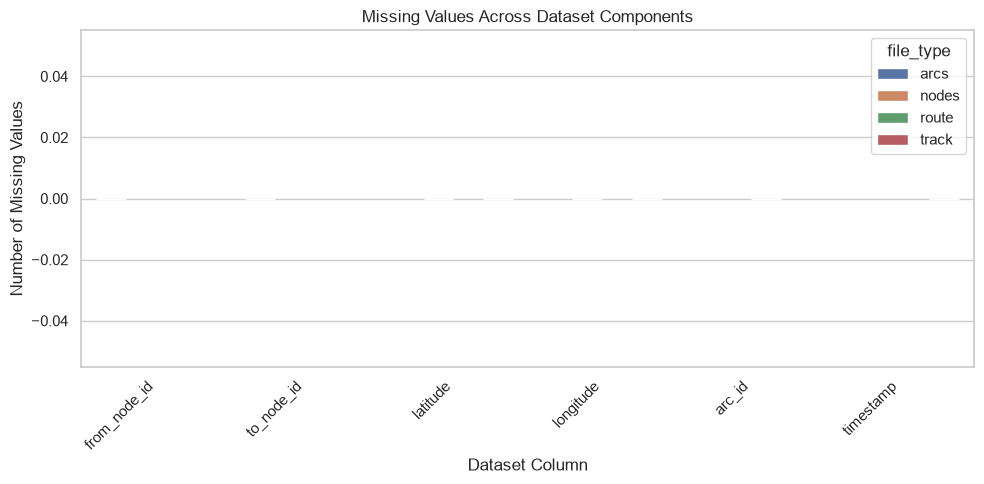

In [5]:
# Calculate missing values for each dataset type

missing_records = []

for partition, trip_ids in [
    ("train", train_trip_ids),
    ("student_test", test_trip_ids)
]:
    for trip_id in trip_ids:

        data = load_trip(partition, trip_id)

        for file_type, dataframe in data.items():

            for column in dataframe.columns:

                missing_records.append({
                    "partition": partition,
                    "trip_id": trip_id,
                    "file_type": file_type,
                    "column": column,
                    "missing_values": int(
                        dataframe[column].isna().sum()
                    )
                })

missing_df = pd.DataFrame(missing_records)

missing_summary = (
    missing_df.groupby(
        ["file_type", "column"]
    )["missing_values"]
    .sum()
    .reset_index()
)

display(missing_summary)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=missing_summary,
    x="column",
    y="missing_values",
    hue="file_type"
)
plt.title("Missing Values Across Dataset Components")
plt.xlabel("Dataset Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs/plots/missing_values.png", dpi=300)
plt.show()

## GPS Observation Analysis

This section studies the number of GPS observations recorded in each trip. The distribution helps understand variations in trajectory length across the dataset.

,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
student_test,10.0,1916.00,1335.43,262.0,917.75,1420.0,2872.00,3958.0
train,80.0,2605.21,3312.35,361.0,945.75,1529.0,2792.75,19313.0


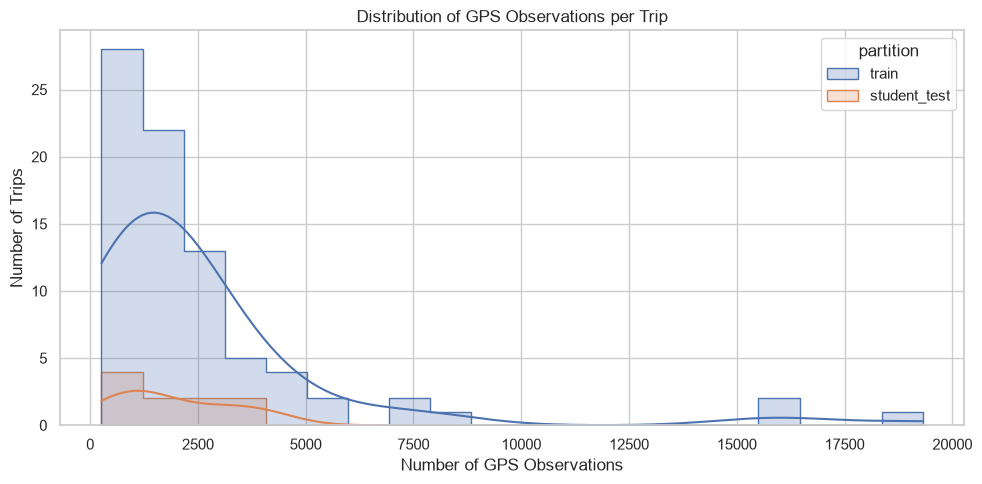

In [6]:
# GPS observation statistics

display(
    trip_summary.groupby("partition")["gps_observations"]
    .describe()
    .round(2)
)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=trip_summary,
    x="gps_observations",
    hue="partition",
    bins=20,
    kde=True,
    element="step"
)

plt.title("Distribution of GPS Observations per Trip")
plt.xlabel("Number of GPS Observations")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs/plots/gps_observation_distribution.png", dpi=300)
plt.show()

## GPS Timestamp Analysis

GPS timestamps are examined to understand the time intervals between consecutive observations. Irregular intervals and non-positive intervals are also identified.

,average_interval,median_interval,irregular_intervals,non_positive_intervals
partition,,,,
student_test,1.091,1.0,264,0
train,5.102,1.0,7289,0


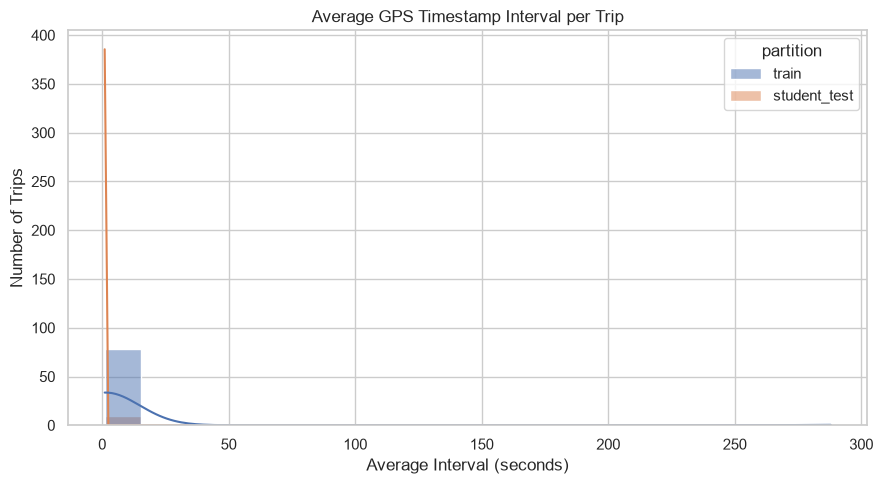

In [7]:
# Calculate timestamp interval statistics

timestamp_records = []

for partition, trip_ids in [
    ("train", train_trip_ids),
    ("student_test", test_trip_ids)
]:
    for trip_id in trip_ids:

        data = load_trip(partition, trip_id)
        clean_track, _ = preprocess_track(data["track"])

        intervals = clean_track["timestamp"].diff().dropna()

        timestamp_records.append({
            "partition": partition,
            "trip_id": trip_id,
            "average_interval": intervals.mean(),
            "median_interval": intervals.median(),
            "irregular_intervals": int((intervals != 1).sum()),
            "non_positive_intervals": int((intervals <= 0).sum())
        })

timestamp_df = pd.DataFrame(timestamp_records)

display(timestamp_df.groupby("partition").agg({
    "average_interval": "mean",
    "median_interval": "mean",
    "irregular_intervals": "sum",
    "non_positive_intervals": "sum"
}).round(3))

plt.figure(figsize=(9, 5))
sns.histplot(
    data=timestamp_df,
    x="average_interval",
    hue="partition",
    bins=20,
    kde=True
)
plt.title("Average GPS Timestamp Interval per Trip")
plt.xlabel("Average Interval (seconds)")
plt.ylabel("Number of Trips")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs/plots/timestamp_intervals.png", dpi=300)
plt.show()

## Road Network Analysis

The road network consists of nodes representing geographic locations and directed arcs connecting these nodes. This section examines the number of nodes and arcs available in each trip.

nodes                                                                   arcs                             \
             count      mean       std     min      25%     50%       75%       max count     mean       std     min   
partition                                                                                                              
student_test  10.0   9068.90   7452.18  1770.0  4908.00  6596.5  11844.25   26635.0  10.0  18504.1  15496.93  3577.0   
train         80.0  24168.56  32272.30   299.0  3487.75  9608.0  28846.75  155003.0  80.0  48461.3  64738.84   649.0   

                                                    route_arcs                                                      
                   25%      50%       75%       max      count   mean     std   min     25%    50%     75%     max  
partition                                                                                                           
student_test  10292.25  13145.0  24818.50   56027.0       10.0  347.7  359.57  95.0  153.50  250.0  357.75  1323.0  
train          7061.75  19526.5  58003.25  307392.0       80.0  391.7  361.17  59.0  168.25  280.0  480.50  2266.0

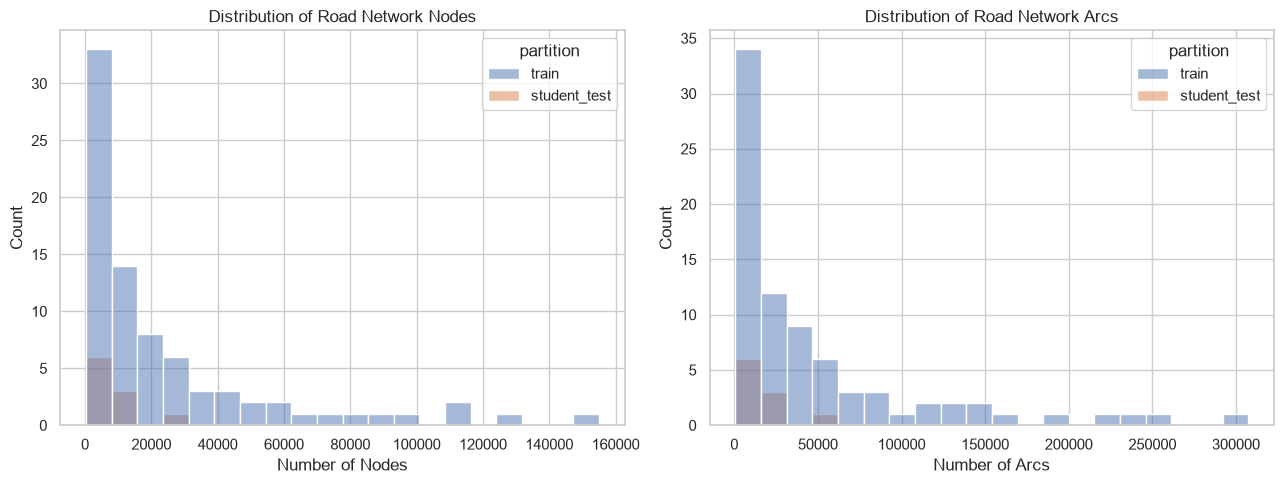

In [8]:
# Road-network statistics

network_summary = trip_summary[
    ["partition", "trip_id", "nodes", "arcs", "route_arcs"]
].copy()

display(
    network_summary.groupby("partition")[
        ["nodes", "arcs", "route_arcs"]
    ].describe().round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=network_summary,
    x="nodes",
    hue="partition",
    bins=20,
    ax=axes[0]
)
axes[0].set_title("Distribution of Road Network Nodes")
axes[0].set_xlabel("Number of Nodes")

sns.histplot(
    data=network_summary,
    x="arcs",
    hue="partition",
    bins=20,
    ax=axes[1]
)
axes[1].set_title("Distribution of Road Network Arcs")
axes[1].set_xlabel("Number of Arcs")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs/plots/road_network_distribution.png", dpi=300)
plt.show()

## Road Network Connectivity

This section examines the directed connections between road-network nodes. Each arc represents a connection from a starting node to an ending node.

,Node ID,In Degree,Out Degree
count,88809.00,88809.00,88809.00
mean,44404.00,1.87,1.87
std,25637.09,0.75,0.75
min,0.00,0.00,0.00
25%,22202.00,1.00,1.00
50%,44404.00,2.00,2.00
75%,66606.00,2.00,2.00
max,88808.00,6.00,6.00


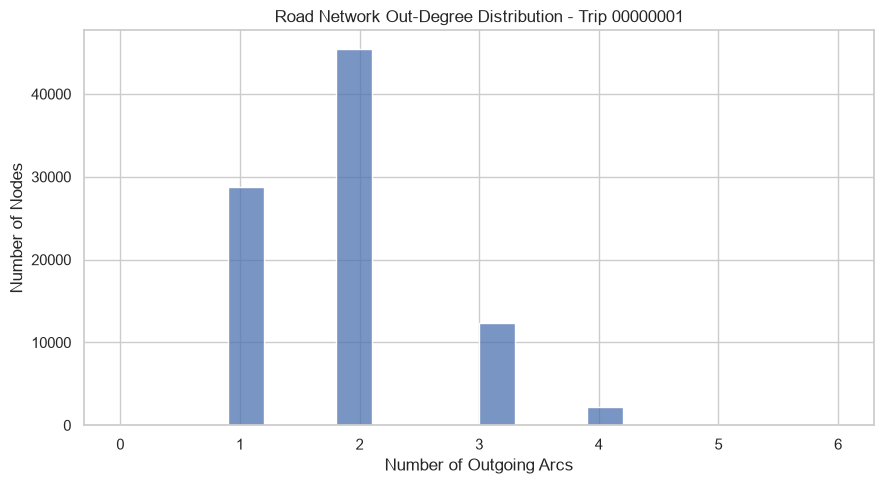

In [9]:
# Inspect connectivity for the sample trip

sample_nodes = sample_data["nodes"]
sample_arcs = sample_data["arcs"]

valid_arcs = sample_arcs.dropna(
    subset=["from_node_id", "to_node_id"]
).copy()

valid_arcs["from_node_id"] = valid_arcs["from_node_id"].astype(int)
valid_arcs["to_node_id"] = valid_arcs["to_node_id"].astype(int)

valid_arcs = valid_arcs[
    valid_arcs["from_node_id"].between(0, len(sample_nodes) - 1)
    & valid_arcs["to_node_id"].between(0, len(sample_nodes) - 1)
]

in_degree = valid_arcs["to_node_id"].value_counts()
out_degree = valid_arcs["from_node_id"].value_counts()

connectivity_summary = pd.DataFrame({
    "Node ID": range(len(sample_nodes))
})

connectivity_summary["In Degree"] = (
    connectivity_summary["Node ID"].map(in_degree).fillna(0)
)

connectivity_summary["Out Degree"] = (
    connectivity_summary["Node ID"].map(out_degree).fillna(0)
)

display(connectivity_summary.describe().round(2))

plt.figure(figsize=(9, 5))
sns.histplot(
    connectivity_summary["Out Degree"],
    bins=20
)
plt.title(f"Road Network Out-Degree Distribution - Trip {sample_trip_id}")
plt.xlabel("Number of Outgoing Arcs")
plt.ylabel("Number of Nodes")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "outputs/plots/network_out_degree.png", dpi=300)
plt.show()

## GPS Trajectory Visualisation

This section visualises the GPS coordinates of a sample trip. The observations are plotted in chronological order to illustrate the recorded movement trajectory.

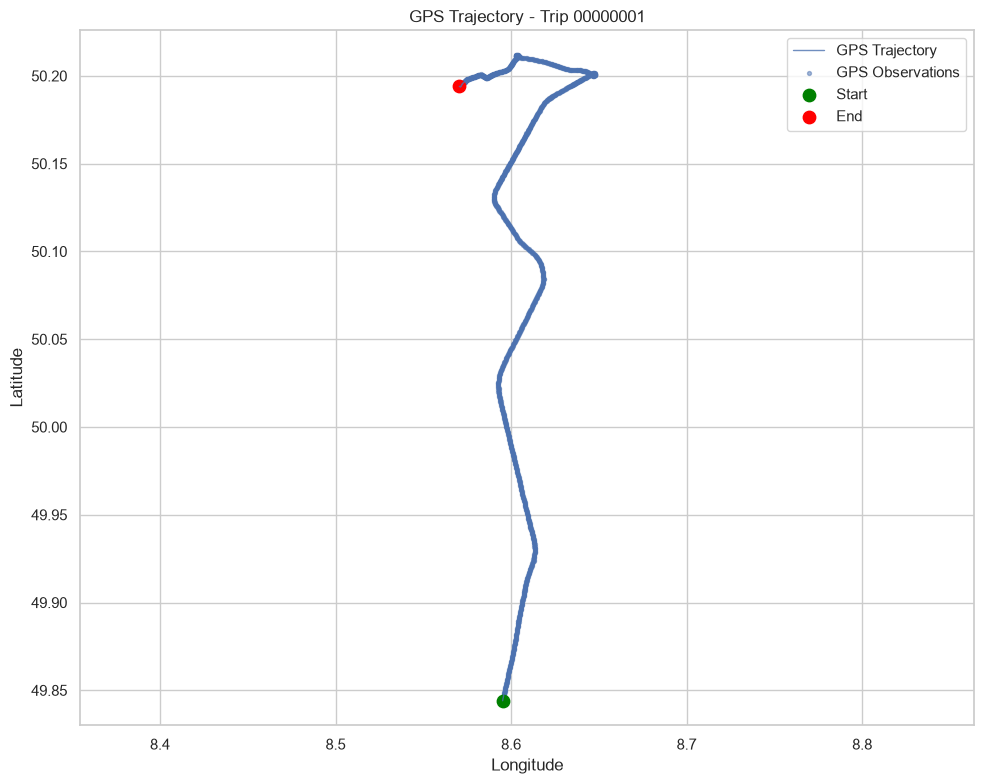

In [10]:
# Plot sample GPS trajectory

sample_track, sample_quality = preprocess_track(
    sample_data["track"]
)

plt.figure(figsize=(10, 8))

plt.plot(
    sample_track["longitude"],
    sample_track["latitude"],
    linewidth=1,
    alpha=0.8,
    label="GPS Trajectory"
)

plt.scatter(
    sample_track["longitude"],
    sample_track["latitude"],
    s=8,
    alpha=0.5,
    label="GPS Observations"
)

plt.scatter(
    sample_track["longitude"].iloc[0],
    sample_track["latitude"].iloc[0],
    color="green",
    s=80,
    label="Start"
)

plt.scatter(
    sample_track["longitude"].iloc[-1],
    sample_track["latitude"].iloc[-1],
    color="red",
    s=80,
    label="End"
)

plt.title(f"GPS Trajectory - Trip {sample_trip_id}")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.axis("equal")
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs/plots/sample_gps_trajectory.png",
    dpi=300
)

plt.show()

## Road Network Visualisation

This section displays the road network associated with the sample trip. Road segments are constructed by connecting the geographic coordinates of their starting and ending nodes.

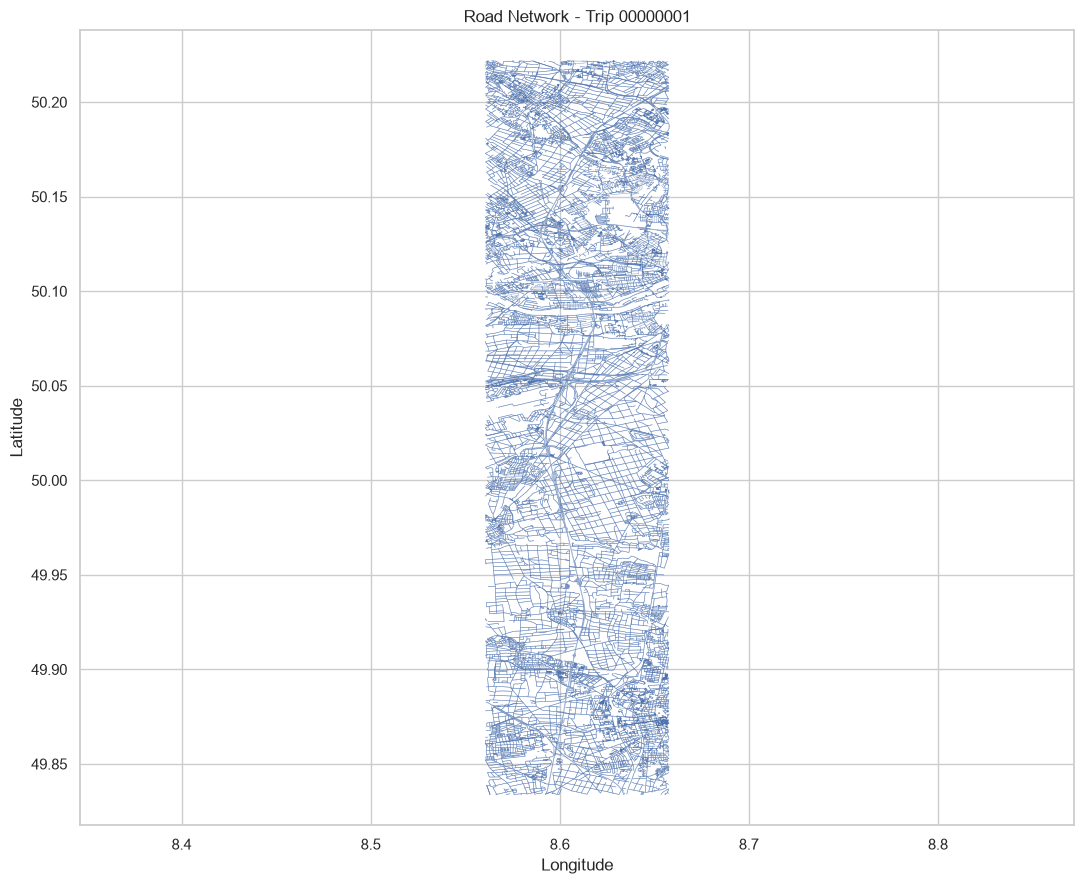

Total nodes: 88809
Valid road arcs: 165790


In [13]:

# Fast road network visualisation

from matplotlib.collections import LineCollection

nodes = sample_data["nodes"]
arcs = sample_data["arcs"]

valid_arcs = arcs.dropna(
    subset=["from_node_id", "to_node_id"]
).copy()

valid_arcs["from_node_id"] = valid_arcs["from_node_id"].astype(int)
valid_arcs["to_node_id"] = valid_arcs["to_node_id"].astype(int)

valid_arcs = valid_arcs[
    valid_arcs["from_node_id"].between(0, len(nodes) - 1)
    & valid_arcs["to_node_id"].between(0, len(nodes) - 1)
]

start_ids = valid_arcs["from_node_id"].to_numpy()
end_ids = valid_arcs["to_node_id"].to_numpy()

coordinates = nodes[["longitude", "latitude"]].to_numpy()

segments = np.stack([
    coordinates[start_ids],
    coordinates[end_ids]
], axis=1)

fig, ax = plt.subplots(figsize=(11, 9))

line_collection = LineCollection(
    segments,
    linewidths=0.4,
    alpha=0.6
)

ax.add_collection(line_collection)
ax.autoscale()
ax.set_aspect("equal", adjustable="datalim")

ax.set_title(f"Road Network - Trip {sample_trip_id}")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs/plots/sample_road_network.png",
    dpi=200
)

plt.show()

print("Total nodes:", len(nodes))
print("Valid road arcs:", len(valid_arcs))


## Candidate Road-Segment Coverage

Candidate generation identifies road segments located near each GPS observation. This section compares candidate coverage at search radii of 30m, 50m and 75m.

In [14]:
# Load candidate-generation statistics

candidate_stats = []

for partition in ["train", "student_test"]:
    for radius in [30, 50, 75]:

        path = (
            PROJECT_ROOT
            / "outputs"
            / "reports"
            / f"{partition}_candidate_stats_r{radius}.csv"
        )

        if path.exists():
            stats = pd.read_csv(
                path,
                dtype={"trip_id": str}
            )
            candidate_stats.append(stats)

candidate_stats_df = pd.concat(
    candidate_stats,
    ignore_index=True
)

display(candidate_stats_df.head())
print("Total candidate-stat records:", len(candidate_stats_df))

,partition,trip_id,radius_m,gps_observations,observations_with_candidates,zero_candidate_observations,average_candidates_per_observation,maximum_candidates_per_observation,candidate_rows,processing_time_seconds
0,train,00000001,30,1315,1315,0,5.409886,10,7114,56.371743
1,train,00000002,30,7243,6368,875,5.539141,10,40120,56.371743
2,train,00000003,30,821,821,0,8.024361,10,6588,56.371743
3,train,00000004,30,1064,1028,36,4.664474,10,4963,56.371743
4,train,00000005,30,1045,1045,0,2.288038,9,2391,56.371743


Total candidate-stat records: 270


## Candidate Coverage Comparison

The candidate coverage at different search radii is compared to understand how increasing the search radius affects the number of GPS observations with available road-segment candidates.

In [15]:
# Aggregate candidate coverage

coverage_summary = (
    candidate_stats_df.groupby(
        ["partition", "radius_m"]
    )
    .agg(
        total_observations=("gps_observations", "sum"),
        observations_with_candidates=(
            "observations_with_candidates", "sum"
        ),
        zero_candidate_observations=(
            "zero_candidate_observations", "sum"
        ),
        total_candidate_rows=("candidate_rows", "sum")
    )
    .reset_index()
)

coverage_summary["coverage_percentage"] = (
    coverage_summary["observations_with_candidates"]
    / coverage_summary["total_observations"] * 100
)

display(coverage_summary.round(2))

,partition,radius_m,total_observations,observations_with_candidates,zero_candidate_observations,total_candidate_rows,coverage_percentage
0,student_test,30,19160,19055,105,98537,99.45
1,student_test,50,19160,19160,0,131528,100.00
2,student_test,75,19160,19160,0,149935,100.00
3,train,30,208417,188137,20280,939332,90.27
4,train,50,208417,190187,18230,1228186,91.25
5,train,75,208417,194809,13608,1452129,93.47


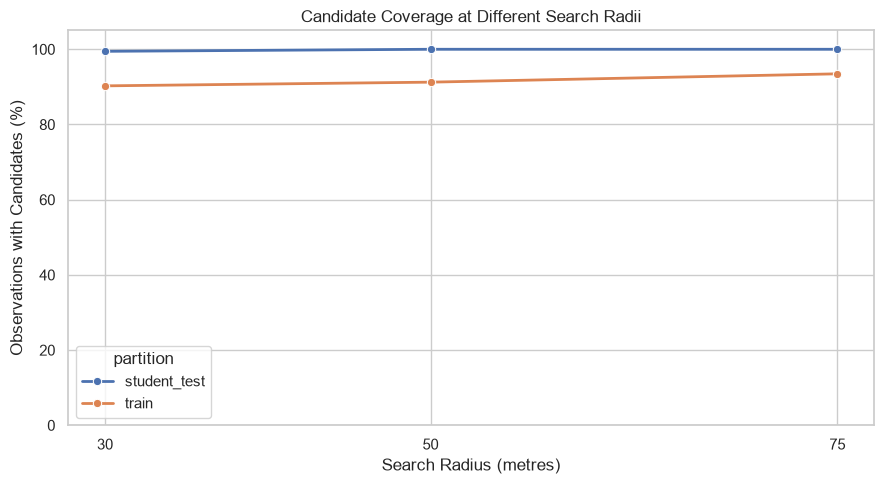

In [16]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=coverage_summary,
    x="radius_m",
    y="coverage_percentage",
    hue="partition",
    marker="o",
    linewidth=2
)

plt.title("Candidate Coverage at Different Search Radii")
plt.xlabel("Search Radius (metres)")
plt.ylabel("Observations with Candidates (%)")
plt.xticks([30, 50, 75])
plt.ylim(0, 105)
plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "outputs/plots/candidate_coverage.png",
    dpi=300
)

plt.show()

## Zero-Candidate Observation Analysis

Some GPS observations may not have any road-segment candidates within the selected search radius. This section identifies trips with zero-candidate observations and examines how their frequency changes across search radii.

In [17]:
# Identify trips with zero-candidate observations

zero_candidate_trips = candidate_stats_df[
    candidate_stats_df["zero_candidate_observations"] > 0
].copy()

zero_candidate_trips = zero_candidate_trips.sort_values(
    "zero_candidate_observations",
    ascending=False
)

display(zero_candidate_trips.head(20))

print(
    "Trip-radius combinations with zero-candidate observations:",
    len(zero_candidate_trips)
)

,partition,trip_id,radius_m,gps_observations,observations_with_candidates,zero_candidate_observations,average_candidates_per_observation,maximum_candidates_per_observation,candidate_rows,processing_time_seconds
44,train,00000054,30,19313,2713,16600,0.930099,10,17963,56.371743
124,train,00000054,50,19313,2794,16519,1.205147,10,23275,86.650898
204,train,00000054,75,19313,6421,12892,2.234143,10,43148,60.792873
67,train,00000084,30,16031,15024,1007,3.838937,10,61542,56.371743
1,train,00000002,30,7243,6368,875,5.539141,10,40120,56.371743
147,train,00000084,50,16031,15449,582,5.068180,10,81248,86.650898
81,train,00000002,50,7243,6733,510,7.372360,10,53398,86.650898
161,train,00000002,75,7243,6914,329,8.435455,10,61098,60.792873
26,train,00000033,30,5844,5544,300,5.177105,10,30255,56.371743
16,train,00000021,30,15783,15483,300,2.630489,10,41517,56.371743


Trip-radius combinations with zero-candidate observations: 77


## Route Connectivity Diagnostics

This section examines the route-gap diagnostic report generated during preprocessing. It identifies consecutive ground-truth route arcs whose endpoints do not connect directly in the supplied road network.

In [18]:
# Load route-gap diagnostics

route_gap_path = (
    PROJECT_ROOT
    / "outputs"
    / "reports"
    / "route_gap_gps_diagnostics.csv"
)

route_gaps = pd.read_csv(route_gap_path)

print("Route-gap records:", len(route_gaps))
display(route_gaps.head(15))

print("\nRecords by partition:")
display(route_gaps["partition"].value_counts())

Route-gap records: 13


,partition,trip_id,route_position,path_distance_m,path_edges,nearest_gps_distance_m,gps_points_within_30m
0,train,2,53,1056.950640,41,0.365772,178
1,train,19,94,364.341444,17,3.258781,15
2,train,19,151,512.845403,12,0.111245,16
3,train,19,300,600.328042,6,6.038354,12
4,train,33,164,92.472893,1,3.195390,452
5,train,41,12,413.688937,6,3.212437,31
6,train,42,1212,68.488975,1,2.735507,13
7,train,69,153,77.546817,6,19.670589,4
8,train,75,31,925.264580,18,0.765765,197
9,train,75,62,1211.533477,27,0.943794,293



Records by partition:


partition
train           12
student_test     1
Name: count, dtype: int64

## EDA Summary

The analysis results are consolidated into summary tables for further inspection and use during project development.

In [19]:
# Save EDA analysis outputs

report_dir = PROJECT_ROOT / "outputs" / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

trip_summary.to_csv(
    report_dir / "eda_trip_summary.csv",
    index=False
)

quality_df.to_csv(
    report_dir / "eda_data_quality.csv",
    index=False
)

missing_summary.to_csv(
    report_dir / "eda_missing_values.csv",
    index=False
)

timestamp_df.to_csv(
    report_dir / "eda_timestamp_analysis.csv",
    index=False
)

network_summary.to_csv(
    report_dir / "eda_network_summary.csv",
    index=False
)

coverage_summary.to_csv(
    report_dir / "eda_candidate_coverage.csv",
    index=False
)

print("EDA summary reports saved successfully.")

EDA summary reports saved successfully.


## Conclusion

The exploratory data analysis provides an overview of the GPS trajectories and road-network structure used in PathSnap.

The analysis examines the distribution of trips, GPS observations, timestamp intervals, missing values, road-network nodes and arcs, and candidate road-segment coverage.

The trajectory and road-network visualisations provide an initial understanding of the spatial characteristics of the dataset.

Candidate coverage comparisons at different search radii help identify observations that may be difficult to match to the supplied road network.

These findings provide a foundation for subsequent route reconstruction, model development and evaluation.

## Integration notes for feature engineering and binary labelling

Use `observation_id` to join cleaned GPS rows to candidate rows. Do not shift or renumber IDs after invalid observations are removed. The original numeric timestamp should be preserved. Candidate-generation coverage describes candidate availability only; it is not ground-truth route-segment coverage. Route-derived positive labels require separate chronological route/GPS alignment and must not enter predictive feature calculations. Trips with broken route connections, irregular sampling, or candidate misses should be surfaced to label-alignment diagnostics.